# Tree-Aware Heuristic Beam-Width Comparison

This notebook measures how beam width affects the error and runtime of the tree-aware alternating heuristic. Every beam width receives the same benchmark cases, sensor budgets, initial allocation, stopping threshold, and iteration limit.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

# Find the module folder from the repository root or this folder.
working_directory = Path.cwd().resolve()
MODULE_DIRECTORY = (
    working_directory / "min-error-sequential"
    if (working_directory / "min-error-sequential").is_dir()
    else working_directory
)
if str(MODULE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(MODULE_DIRECTORY))

from beam_width_analysis import (
    beam_width_summary,
    make_beam_width_plot,
    run_beam_width_study,
)

## Run settings

The current test draws five seeded random cases from every $K,M$ cell across $K=3,\ldots,7$ and $M=3,\ldots,8$, giving 150 cases per dataset. This includes the harder cases where beam width is more likely to matter. To run all 2,700 cases later, set `RUN_ALL_REPLICATES = True`; the projected serial runtime is roughly 11 hours.

In [2]:
# Compare the expanded one-dimensional and two-dimensional benchmarks.
DATASETS = ["benchmark_1d", "benchmark_2d"]

# False runs a small representative test; True runs every generated case.
RUN_ALL_REPLICATES = False
REPLICATES_PER_CELL = None
RUN_SCOPE = "full" if RUN_ALL_REPLICATES else "test"
TEST_K_VALUES = None if RUN_ALL_REPLICATES else (3, 4, 5, 6, 7)
TEST_M_VALUES = None if RUN_ALL_REPLICATES else (3, 4, 5, 6, 7, 8)
RANDOM_CASES_PER_K_M = None if RUN_ALL_REPLICATES else 5
CASE_SAMPLE_SEED = 20260813

# Keep this study separate from the main algorithm comparison.
RESULTS_ROOT = MODULE_DIRECTORY / "results" / "heuristic_beam_width"

print("Run mode:", "full" if RUN_ALL_REPLICATES else "test")
print("Selected K values:", TEST_K_VALUES or "all")
print("Selected M values:", TEST_M_VALUES or "all")
print("Random cases per K,M cell:", RANDOM_CASES_PER_K_M or "all")
print("Case-sampling seed:", CASE_SAMPLE_SEED)
print("Results directory:", RESULTS_ROOT)

Run mode: test
Selected K values: (3, 4, 5, 6, 7)
Selected M values: (3, 4, 5, 6, 7, 8)
Random cases per K,M cell: 5
Case-sampling seed: 20260813
Results directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/heuristic_beam_width


## Heuristic configuration

Only `BEAM_WIDTHS` changes between runs. The shared random seed gives every width the same near-uniform starting allocation and reproducible random move order.

In [3]:
# Number of partial decision trees retained after each beam expansion.
BEAM_WIDTHS = (1, 3, 5)

# Shared allocation-search settings for every beam width.
MAX_ITERATIONS = 5
IMPROVEMENT_THRESHOLD = 1e-3
INITIALIZATION = "near_uniform"
RANDOM_SEED = 0
PROGRESS_EVERY = 25

print("Beam widths:", BEAM_WIDTHS)
print("Maximum iterations:", MAX_ITERATIONS)
print("Improvement threshold:", IMPROVEMENT_THRESHOLD)
print("Initialization:", INITIALIZATION, "seed:", RANDOM_SEED)
print("Progress interval:", PROGRESS_EVERY, "cases")

Beam widths: (1, 3, 5)
Maximum iterations: 5
Improvement threshold: 0.0001
Initialization: near_uniform seed: 0
Progress interval: 25 cases


## Run the beam-width study

In [4]:
records_by_dataset = {}
for dataset in DATASETS:
    display(Markdown(f"### Running `{dataset}`"))
    records_by_dataset[dataset] = run_beam_width_study(
        dataset,
        beam_widths=BEAM_WIDTHS,
        replicates_per_cell=REPLICATES_PER_CELL,
        results_root=RESULTS_ROOT,
        max_iterations=MAX_ITERATIONS,
        improvement_threshold=IMPROVEMENT_THRESHOLD,
        initialization=INITIALIZATION,
        random_seed=RANDOM_SEED,
        progress_every=PROGRESS_EVERY,
        k_values=TEST_K_VALUES,
        m_values=TEST_M_VALUES,
        random_cases_per_k_m=RANDOM_CASES_PER_K_M,
        case_sample_seed=CASE_SAMPLE_SEED,
    )

### Running `benchmark_1d`

benchmark_1d: completed case 1/150 (gaussian, K=3, M=3)
benchmark_1d: completed case 25/150 (sinusoidal, K=3, M=7)
benchmark_1d: completed case 50/150 (sinusoidal, K=4, M=6)
benchmark_1d: completed case 75/150 (gaussian, K=5, M=5)
benchmark_1d: completed case 100/150 (quadratic, K=6, M=4)
benchmark_1d: completed case 125/150 (sinusoidal, K=7, M=3)
benchmark_1d: completed case 150/150 (sinusoidal, K=7, M=8)


### Running `benchmark_2d`

benchmark_2d: completed case 1/150 (gaussian, K=3, M=3)
benchmark_2d: completed case 25/150 (sinusoidal, K=3, M=7)
benchmark_2d: completed case 50/150 (sinusoidal, K=4, M=6)
benchmark_2d: completed case 75/150 (gaussian, K=5, M=5)
benchmark_2d: completed case 100/150 (quadratic, K=6, M=4)
benchmark_2d: completed case 125/150 (sinusoidal, K=7, M=3)
benchmark_2d: completed case 150/150 (sinusoidal, K=7, M=8)


## Numerical summary

In [5]:
summary_lines = [
    "| Dataset | Beam width | Runs | Mean final error | Maximum error | Mean runtime (s) |",
    "|---|---:|---:|---:|---:|---:|",
]
for dataset, records in records_by_dataset.items():
    for row in beam_width_summary(records):
        summary_lines.append(
            f"| {dataset} | {row['beam_width']} | {row['runs']} | "
            f"{row['mean_final_error']:.5f} | "
            f"{row['maximum_final_error']:.5f} | "
            f"{row['mean_seconds']:.5f} |"
        )
display(Markdown("\n".join(summary_lines)))

| Dataset | Beam width | Runs | Mean final error | Maximum error | Mean runtime (s) |
|---|---:|---:|---:|---:|---:|
| benchmark_1d | 1 | 595 | 0.37478 | 0.76445 | 0.02664 |
| benchmark_1d | 3 | 595 | 0.36489 | 0.76433 | 0.07029 |
| benchmark_1d | 5 | 595 | 0.35941 | 0.76433 | 0.11433 |
| benchmark_2d | 1 | 598 | 0.39936 | 0.80595 | 0.02677 |
| benchmark_2d | 3 | 598 | 0.39130 | 0.80297 | 0.06944 |
| benchmark_2d | 5 | 598 | 0.38651 | 0.80297 | 0.11712 |

## Mean final error by sensor budget

The left panel shows 1D and the right panel shows 2D. Every line represents one beam width. Values are averaged over all field families, $K$ values, and $M$ values.

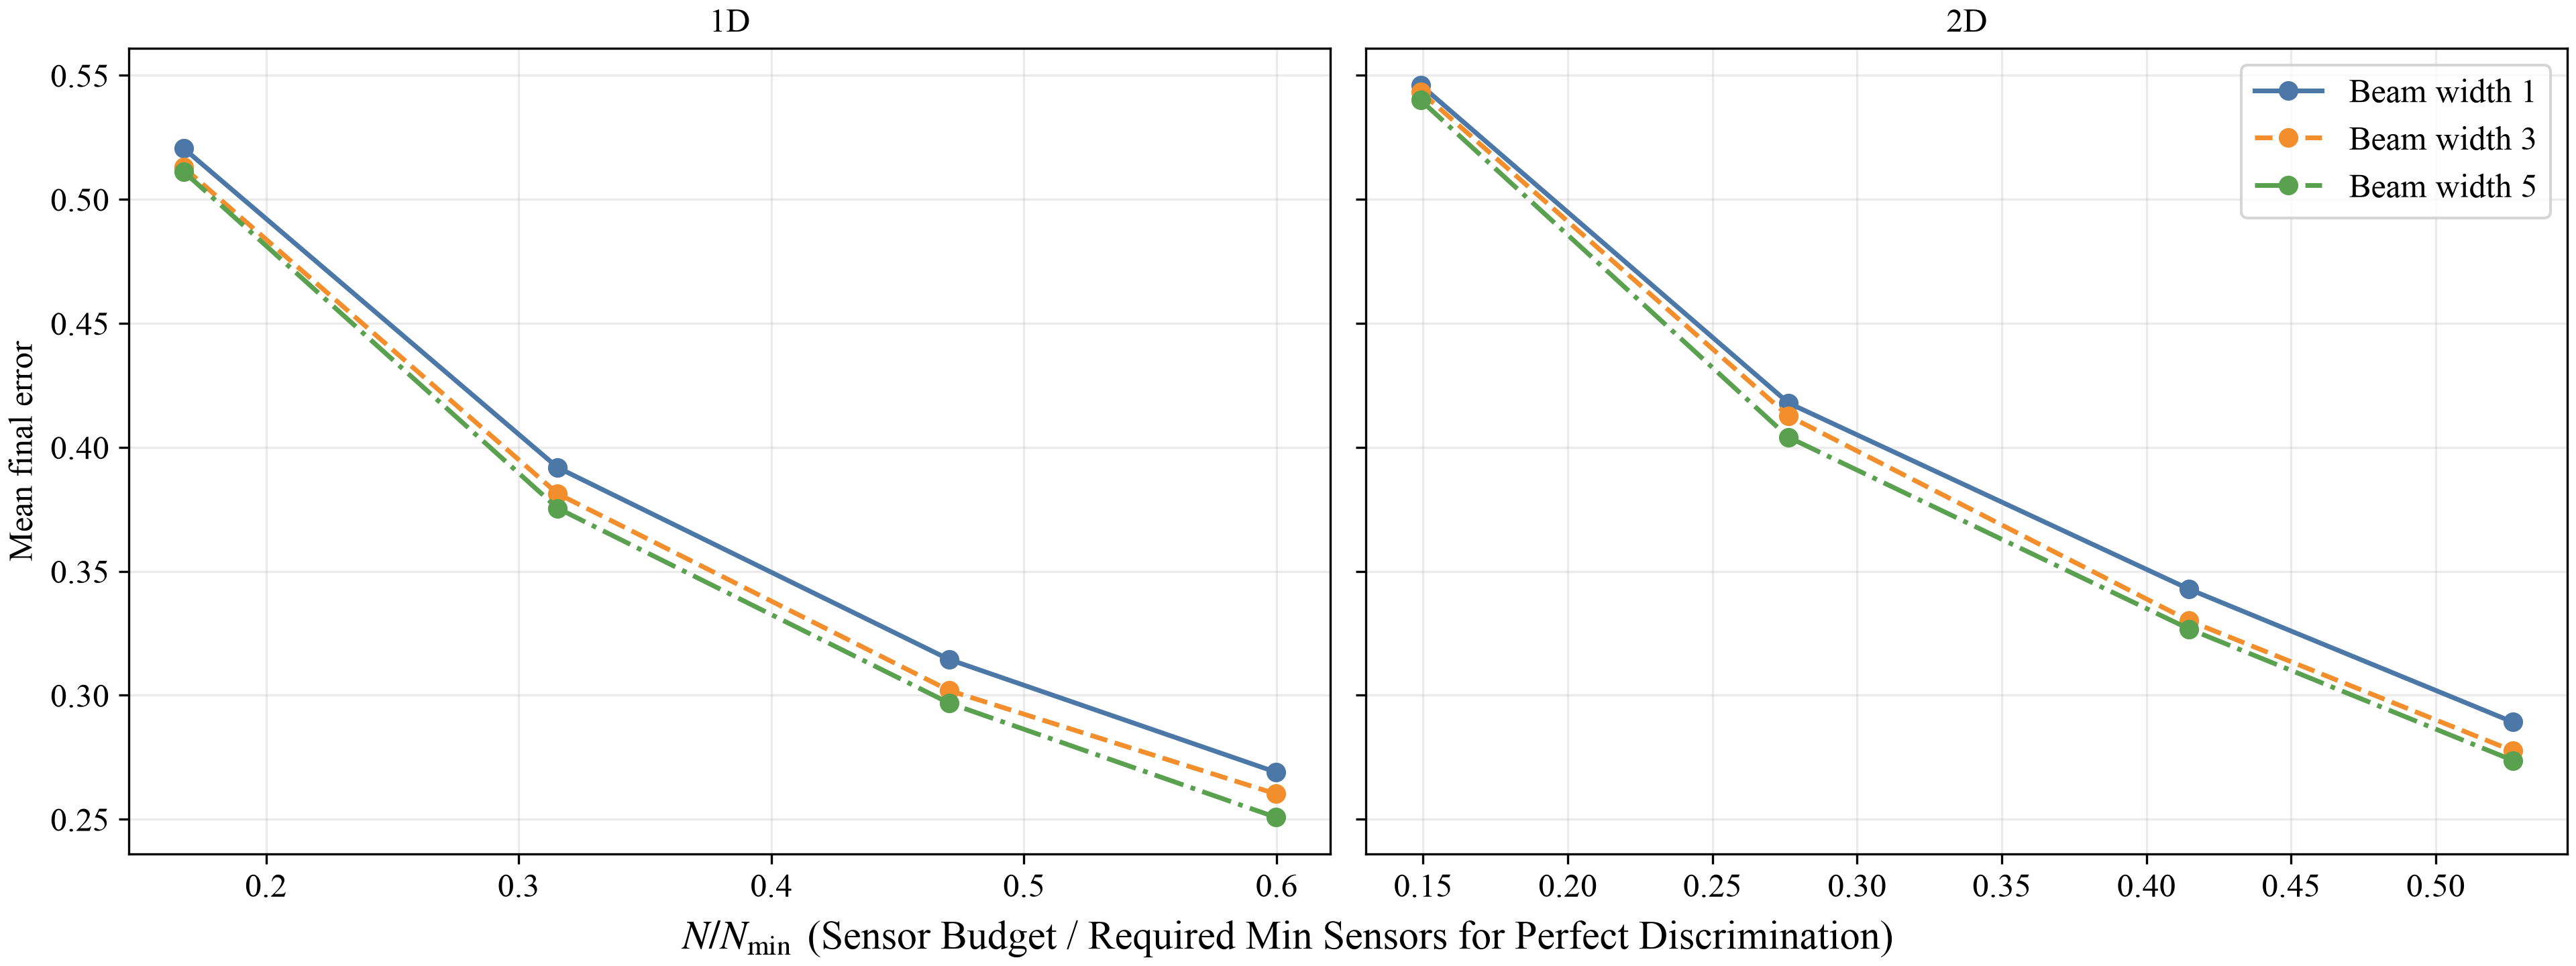

In [6]:
figure = make_beam_width_plot(
    records_by_dataset,
    results_root=RESULTS_ROOT,
    run_scope=RUN_SCOPE,
)
plt.close(figure)

# Load the saved PNG so the figure is always embedded in the notebook.
figure_path = (
    RESULTS_ROOT
    / f"results_summary_heuristic_beam_width_{RUN_SCOPE}"
    / "figures"
    / "mean_error_curves_by_beam_width.png"
)
display(Image(filename=str(figure_path)))

## Saved files

```text
results/heuristic_beam_width/
├── benchmark_1d_results_<test|full>/tables/
├── benchmark_2d_results_<test|full>/tables/
└── results_summary_heuristic_beam_width_<test|full>/figures/
    ├── mean_error_curves_by_beam_width.png
    └── mean_error_curves_by_beam_width.pdf
```